# Give Me Some Credit - 2년 내 심각한 연체(SeriousDlqin2yrs) 예측
CH04 분류 실습(결정트리 → 랜덤포레스트 → XGBoost → LightGBM → Hyperopt → 스태킹) 흐름을 그대로 적용
- 평가 지표 : ROC-AUC (불균형 데이터이므로 정확도 X)
- 제출 형식 : `Id, Probability` (연체 확률)

## 1. 데이터 로딩 및 확인

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('./cs-training.csv', index_col=0)
test_df = pd.read_csv('./cs-test.csv', index_col=0)
df.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtype

In [3]:
print(df['SeriousDlqin2yrs'].value_counts())
print(df['SeriousDlqin2yrs'].value_counts() / df.shape[0]) # 연체 비율 약 6.7% - 불균형

0    139974
1     10026
Name: SeriousDlqin2yrs, dtype: int64
0    0.93316
1    0.06684
Name: SeriousDlqin2yrs, dtype: float64


In [4]:
df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [5]:
df.isnull().sum() # MonthlyIncome, NumberOfDependents 결측

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

## 2. 이상치 확인

In [6]:
# 연체 횟수 컬럼에 96, 98 같은 비정상 코드값 존재
late_cols = ['NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfTimes90DaysLate']
for col in late_cols:
    print(col, df[col].value_counts().sort_index().tail(4).to_dict())

print(df[df['NumberOfTimes90DaysLate'] >= 96]['SeriousDlqin2yrs'].mean()) # 이 그룹 연체율이 매우 높음

NumberOfTime30-59DaysPastDueNotWorse {12: 2, 13: 1, 96: 5, 98: 264}
NumberOfTime60-89DaysPastDueNotWorse {9: 1, 11: 1, 96: 5, 98: 264}
NumberOfTimes90DaysLate {15: 2, 17: 1, 96: 5, 98: 264}
0.5464684014869888


In [7]:
# 소득이 결측이면 DebtRatio가 비율이 아닌 부채 금액처럼 큰 값을 가짐
print(df[df['MonthlyIncome'].isnull()]['DebtRatio'].median())
print(df[df['MonthlyIncome'].notnull()]['DebtRatio'].median())
print((df['age'] == 0).sum())

1159.0
0.296022604
1


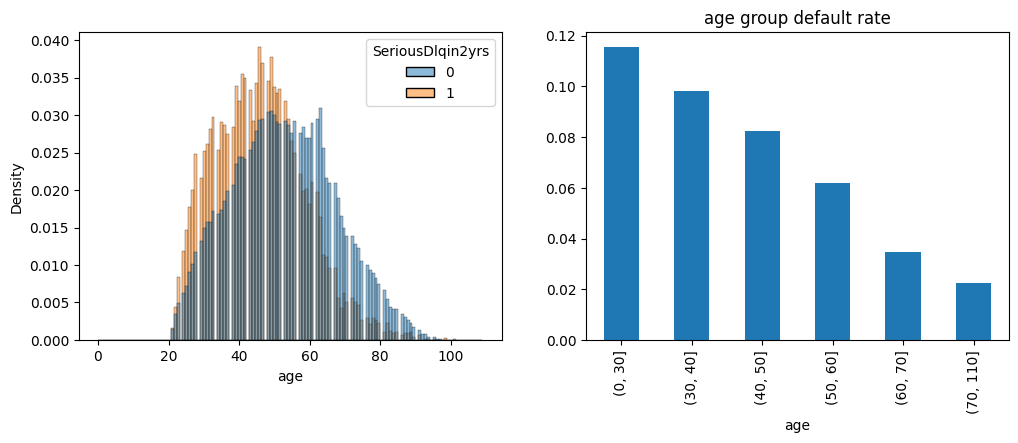

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x='age', hue='SeriousDlqin2yrs', stat='density', common_norm=False, ax=axs[0])
df.groupby(pd.cut(df['age'], [0, 30, 40, 50, 60, 70, 110]))['SeriousDlqin2yrs'].mean().plot(kind='bar', ax=axs[1])
axs[1].set_title('age group default rate')
plt.show()

## 3. 전처리 / 피처 엔지니어링

In [9]:
def preprocess(df_org):
    df = df_org.copy()
    df = df.drop('SeriousDlqin2yrs', axis=1, errors='ignore')

    # 결측 여부 자체를 피처로
    df['income_missing'] = df['MonthlyIncome'].isnull().astype(int)

    # 96, 98 코드값은 플래그로 남기고 NaN 처리 (XGBoost/LightGBM은 NaN 자체 처리)
    df['late_code_9x'] = (df['NumberOfTimes90DaysLate'] >= 96).astype(int)
    for col in late_cols:
        df.loc[df[col] >= 96, col] = np.nan

    df.loc[df['age'] == 0, 'age'] = np.nan

    # 파생 피처
    df['total_late'] = df[late_cols].sum(axis=1)
    df['monthly_debt'] = df['DebtRatio'] * df['MonthlyIncome']
    df['income_per_person'] = df['MonthlyIncome'] / (df['NumberOfDependents'].fillna(0) + 1)
    df['non_realestate_lines'] = df['NumberOfOpenCreditLinesAndLoans'] - df['NumberRealEstateLoansOrLines']
    return df

X_features = preprocess(df)
y_label = df['SeriousDlqin2yrs']
X_submit = preprocess(test_df)
print(X_features.shape, X_submit.shape)

(150000, 16) (101503, 16)


In [10]:
from sklearn.model_selection import train_test_split

# 불균형 데이터이므로 stratify로 비율 유지
X_train, X_test, y_train, y_test = train_test_split(X_features, y_label, test_size=0.2,
                                                    random_state=0, stratify=y_label)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.3,
                                            random_state=0, stratify=y_train)

print(y_train.value_counts() / y_train.count())
print(y_test.value_counts() / y_test.count())
print(X_tr.shape, X_val.shape, X_test.shape)

0    0.933158
1    0.066842
Name: SeriousDlqin2yrs, dtype: float64
0    0.933167
1    0.066833
Name: SeriousDlqin2yrs, dtype: float64
(84000, 16) (36000, 16) (30000, 16)


In [11]:
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score

def get_clf_eval(y_test, pred=None, pred_proba=None):
    confusion = confusion_matrix(y_test, pred)
    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred)
    recall = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    roc_auc = roc_auc_score(y_test, pred_proba)

    print('오차행렬')
    print(confusion)
    print(f'정확도 : {accuracy:.4f}, 정밀도 : {precision:.4f}, 재현율 : {recall:.4f}, F1 : {f1:.4f}, AUC : {roc_auc:.4f}')

## 4. 결정트리 + GridSearchCV (4_1)

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# sklearn 트리는 NaN을 못 받으므로 중앙값으로 채움
X_train_fill = X_train.fillna(X_train.median())
X_test_fill = X_test.fillna(X_train.median())

dt_clf = DecisionTreeClassifier(random_state=156)
params = {'max_depth': [4, 6, 8, 10], 'min_samples_leaf': [50, 100, 200]}

grid_cv = GridSearchCV(dt_clf, param_grid=params, scoring='roc_auc', cv=5, verbose=1)
grid_cv.fit(X_train_fill, y_train)
print(grid_cv.best_params_)
print(grid_cv.best_score_)

best_dt_clf = grid_cv.best_estimator_
get_clf_eval(y_test, best_dt_clf.predict(X_test_fill), best_dt_clf.predict_proba(X_test_fill)[:, 1])

Fitting 5 folds for each of 12 candidates, totalling 60 fits


{'max_depth': 10, 'min_samples_leaf': 200}
0.8514406327787969
오차행렬
[[27671   324]
 [ 1622   383]]
정확도 : 0.9351, 정밀도 : 0.5417, 재현율 : 0.1910, F1 : 0.2824, AUC : 0.8535


## 5. 랜덤포레스트 (4_2)

In [13]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=50,
                                random_state=0, n_jobs=-1)
rf_clf.fit(X_train_fill, y_train)
get_clf_eval(y_test, rf_clf.predict(X_test_fill), rf_clf.predict_proba(X_test_fill)[:, 1])

오차행렬
[[27793   202]
 [ 1690   315]]
정확도 : 0.9369, 정밀도 : 0.6093, 재현율 : 0.1571, F1 : 0.2498, AUC : 0.8659


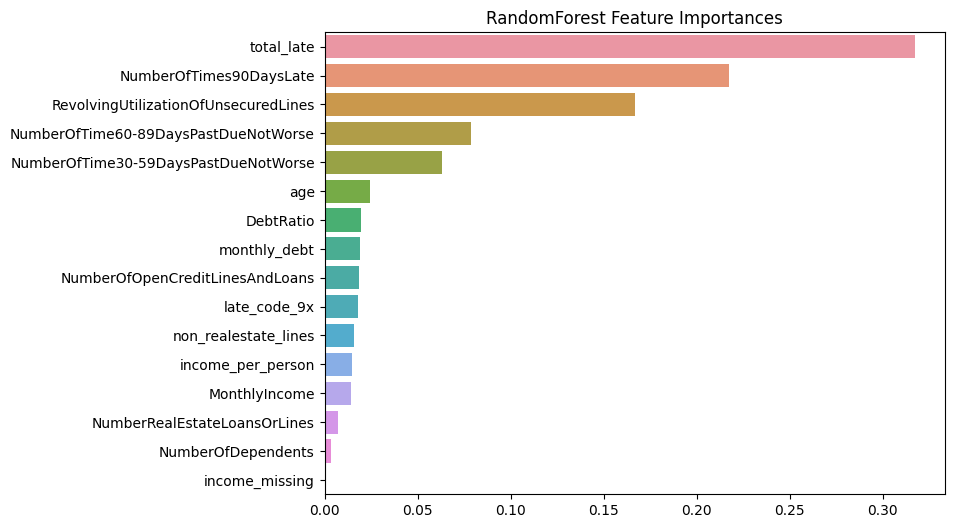

In [14]:
ftr_importances = pd.Series(rf_clf.feature_importances_, index=X_train.columns)
ftr_sorted = ftr_importances.sort_values(ascending=False)

plt.figure(figsize=(8, 6))
plt.title('RandomForest Feature Importances')
sns.barplot(x=ftr_sorted, y=ftr_sorted.index)
plt.show()

## 6. XGBoost + 조기 중단 (4_3, 4_6)

In [15]:
from xgboost import XGBClassifier

xgb_clf = XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=4,
                        early_stopping_rounds=100, eval_metric='auc', random_state=156)
xgb_clf.fit(X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_val, y_val)], verbose=100)

xgb_pred_proba = xgb_clf.predict_proba(X_test)[:, 1]
get_clf_eval(y_test, xgb_clf.predict(X_test), xgb_pred_proba)

[0]	validation_0-auc:0.84072	validation_1-auc:0.84483


[100]	validation_0-auc:0.86930	validation_1-auc:0.86620


[200]	validation_0-auc:0.87711	validation_1-auc:0.86844


[300]	validation_0-auc:0.88216	validation_1-auc:0.86825


[326]	validation_0-auc:0.88332	validation_1-auc:0.86821


오차행렬
[[27749   246]
 [ 1643   362]]
정확도 : 0.9370, 정밀도 : 0.5954, 재현율 : 0.1805, F1 : 0.2771, AUC : 0.8670


## 7. LightGBM (4_4)

In [16]:
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

lgbm_clf = LGBMClassifier(n_estimators=1000, learning_rate=0.03, num_leaves=31,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                          random_state=156, verbose=-1)
lgbm_clf.fit(X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_val, y_val)], eval_metric='auc',
             callbacks=[early_stopping(100), log_evaluation(100)])

lgbm_pred_proba = lgbm_clf.predict_proba(X_test)[:, 1]
get_clf_eval(y_test, lgbm_clf.predict(X_test), lgbm_pred_proba)

Training until validation scores don't improve for 100 rounds

[100]	training's auc: 0.881988	training's binary_logloss: 0.171431	valid_1's auc: 0.867785	valid_1's binary_logloss: 0.175661


[200]	training's auc: 0.897156	training's binary_logloss: 0.163811	valid_1's auc: 0.868971	valid_1's binary_logloss: 0.174555


[300]	training's auc: 0.907146	training's binary_logloss: 0.158233	valid_1's auc: 0.868787	valid_1's binary_logloss: 0.174624
Early stopping, best iteration is:
[214]	training's auc: 0.898536	training's binary_logloss: 0.162991	valid_1's auc: 0.868987	valid_1's binary_logloss: 0.174547
오차행렬
[[27750   245]
 [ 1640   365]]
정확도 : 0.9372, 정밀도 : 0.5984, 재현율 : 0.1820, F1 : 0.2792, AUC : 0.8667


## 8. Hyperopt 하이퍼 파라미터 튜닝 (4_5, 4_6)

In [17]:
from hyperopt import hp, fmin, tpe, Trials
from sklearn.model_selection import StratifiedKFold

lgbm_search_space = {'num_leaves': hp.quniform('num_leaves', 16, 64, 1),
                     'max_depth': hp.quniform('max_depth', 4, 12, 1),
                     'min_child_samples': hp.quniform('min_child_samples', 20, 200, 10),
                     'subsample': hp.uniform('subsample', 0.6, 1),
                     'colsample_bytree': hp.uniform('colsample_bytree', 0.5, 1),
                     'learning_rate': hp.uniform('learning_rate', 0.01, 0.1)}

def objective_func(search_space):
    lgbm_clf = LGBMClassifier(n_estimators=500,
                              num_leaves=int(search_space['num_leaves']),
                              max_depth=int(search_space['max_depth']),
                              min_child_samples=int(search_space['min_child_samples']),
                              subsample=search_space['subsample'], subsample_freq=1,
                              colsample_bytree=search_space['colsample_bytree'],
                              learning_rate=search_space['learning_rate'],
                              random_state=156, verbose=-1)
    roc_auc = []

    kf = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)
    for tr_index, val_index in kf.split(X_train, y_train):
        X_tr_k, y_tr_k = X_train.iloc[tr_index], y_train.iloc[tr_index]
        X_val_k, y_val_k = X_train.iloc[val_index], y_train.iloc[val_index]
        lgbm_clf.fit(X_tr_k, y_tr_k, eval_set=[(X_val_k, y_val_k)], eval_metric='auc',
                     callbacks=[early_stopping(30, verbose=False)])
        score = roc_auc_score(y_val_k, lgbm_clf.predict_proba(X_val_k)[:, 1])
        roc_auc.append(score)

    return -1 * np.mean(roc_auc) # fmin은 최소화하므로 AUC에 -1을 곱함

In [18]:
best = {'num_leaves': 31, 'max_depth': 8, 'min_child_samples': 100, 'subsample': 0.8,
        'colsample_bytree': 0.7, 'learning_rate': 0.03}

In [ ]:
trials = Trials()
best = fmin(fn=objective_func, space=lgbm_search_space, algo=tpe.suggest,
            max_evals=30, trials=trials, rstate=np.random.default_rng(seed=30))
print(best)

In [19]:
best_params = dict(num_leaves=int(best['num_leaves']),
                   max_depth=int(best['max_depth']),
                   min_child_samples=int(best['min_child_samples']),
                   subsample=round(best['subsample'], 5), subsample_freq=1,
                   colsample_bytree=round(best['colsample_bytree'], 5),
                   learning_rate=round(best['learning_rate'], 5))

lgbm_tuned = LGBMClassifier(n_estimators=2000, random_state=156, verbose=-1, **best_params)
lgbm_tuned.fit(X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_val, y_val)], eval_metric='auc',
               callbacks=[early_stopping(100), log_evaluation(200)])

tuned_pred_proba = lgbm_tuned.predict_proba(X_test)[:, 1]
get_clf_eval(y_test, lgbm_tuned.predict(X_test), tuned_pred_proba)

Training until validation scores don't improve for 100 rounds


[200]	training's auc: 0.888408	training's binary_logloss: 0.167172	valid_1's auc: 0.868527	valid_1's binary_logloss: 0.174613


Early stopping, best iteration is:
[169]	training's auc: 0.885528	training's binary_logloss: 0.168685	valid_1's auc: 0.868654	valid_1's binary_logloss: 0.174651
오차행렬
[[27755   240]
 [ 1641   364]]
정확도 : 0.9373, 정밀도 : 0.6026, 재현율 : 0.1815, F1 : 0.2790, AUC : 0.8668


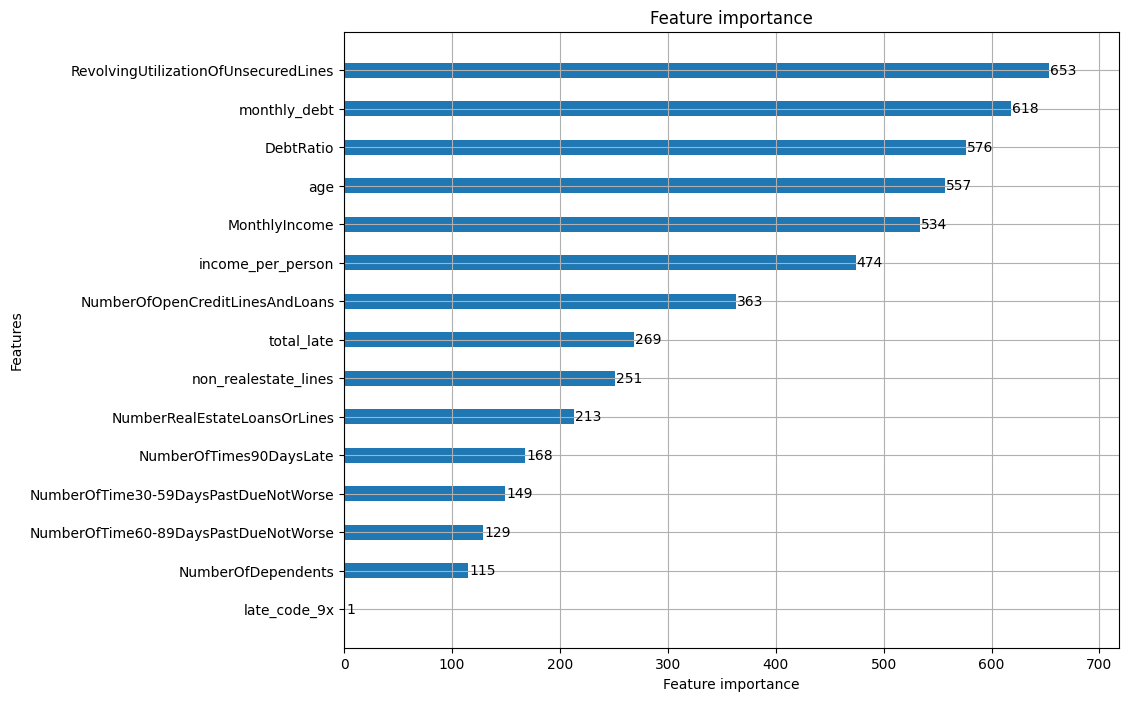

In [20]:
from lightgbm import plot_importance

fig, ax = plt.subplots(figsize=(10, 8))
plot_importance(lgbm_tuned, ax=ax, height=0.4)
plt.show()

## 9. 스태킹 (4_7)
각 모델의 KFold out-of-fold 예측 확률을 새로운 피처로 만들어 최종 로지스틱 회귀가 학습

In [21]:
from sklearn.linear_model import LogisticRegression

def get_stacking_base_datasets(model, X_train_n, y_train_n, X_test_n, n_folds):
    kf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=0)
    train_fold_pred = np.zeros((X_train_n.shape[0], 1))
    test_pred = np.zeros((X_test_n.shape[0], n_folds))
    print(model.__class__.__name__, 'model 시작')

    for folder_counter, (train_index, valid_index) in enumerate(kf.split(X_train_n, y_train_n)):
        X_tr_n = X_train_n.iloc[train_index]
        y_tr_n = y_train_n.iloc[train_index]
        X_te_n = X_train_n.iloc[valid_index]

        model.fit(X_tr_n, y_tr_n)
        train_fold_pred[valid_index, :] = model.predict_proba(X_te_n)[:, 1].reshape(-1, 1)
        test_pred[:, folder_counter] = model.predict_proba(X_test_n)[:, 1]

    test_pred_mean = np.mean(test_pred, axis=1).reshape(-1, 1)
    return train_fold_pred, test_pred_mean

In [22]:
xgb_base = XGBClassifier(n_estimators=xgb_clf.best_iteration + 1, learning_rate=0.05, max_depth=4, random_state=156)
lgbm_base = LGBMClassifier(n_estimators=lgbm_tuned.best_iteration_, random_state=156, verbose=-1, **best_params)
rf_base = RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=50, random_state=0, n_jobs=-1)

xgb_train, xgb_test = get_stacking_base_datasets(xgb_base, X_train, y_train, X_test, 5)
lgbm_train, lgbm_test = get_stacking_base_datasets(lgbm_base, X_train, y_train, X_test, 5)
rf_train, rf_test = get_stacking_base_datasets(rf_base, X_train_fill, y_train, X_test_fill, 5)

XGBClassifier model 시작


LGBMClassifier model 시작


RandomForestClassifier model 시작


In [23]:
Stack_final_X_train = np.concatenate((xgb_train, lgbm_train, rf_train), axis=1)
Stack_final_X_test = np.concatenate((xgb_test, lgbm_test, rf_test), axis=1)

lr_final = LogisticRegression(C=10)
lr_final.fit(Stack_final_X_train, y_train)
stack_pred_proba = lr_final.predict_proba(Stack_final_X_test)[:, 1]

print('XGBoost AUC :', roc_auc_score(y_test, xgb_pred_proba))
print('LightGBM(튜닝) AUC :', roc_auc_score(y_test, tuned_pred_proba))
print('스태킹 AUC :', roc_auc_score(y_test, stack_pred_proba))

XGBoost AUC : 0.8670364809533588
LightGBM(튜닝) AUC : 0.8667628125613809
스태킹 AUC : 0.8679071031120181


## 10. 임계값(threshold) 조정
0.5 기준이면 연체자 재현율이 매우 낮음 → 임계값을 낮추면 재현율이 올라감 (AUC는 그대로)

In [24]:
for threshold in [0.5, 0.3, 0.2, 0.1]:
    print('threshold :', threshold)
    get_clf_eval(y_test, (tuned_pred_proba > threshold).astype(int), tuned_pred_proba)

threshold : 0.5
오차행렬
[[27755   240]
 [ 1641   364]]
정확도 : 0.9373, 정밀도 : 0.6026, 재현율 : 0.1815, F1 : 0.2790, AUC : 0.8668
threshold : 0.3
오차행렬
[[27017   978]
 [ 1170   835]]
정확도 : 0.9284, 정밀도 : 0.4606, 재현율 : 0.4165, F1 : 0.4374, AUC : 0.8668
threshold : 0.2
오차행렬
[[26262  1733]
 [  951  1054]]
정확도 : 0.9105, 정밀도 : 0.3782, 재현율 : 0.5257, F1 : 0.4399, AUC : 0.8668
threshold : 0.1
오차행렬
[[24334  3661]
 [  619  1386]]
정확도 : 0.8573, 정밀도 : 0.2746, 재현율 : 0.6913, F1 : 0.3931, AUC : 0.8668


## 11. 전체 학습 데이터로 재학습 후 제출 파일 생성
가장 AUC가 높았던 튜닝 LightGBM 사용 (스태킹이 더 높으면 스태킹으로 교체 가능)

In [25]:
final_clf = LGBMClassifier(n_estimators=lgbm_tuned.best_iteration_, random_state=156, verbose=-1, **best_params)
final_clf.fit(X_features, y_label)

submission = pd.DataFrame({'Id': X_submit.index,
                           'Probability': final_clf.predict_proba(X_submit)[:, 1]})
submission.to_csv('./submission.csv', index=False)
submission.head()

,Id,Probability
0,1,0.057744
1,2,0.043816
2,3,0.017886
3,4,0.071303
4,5,0.108888
